# Experiment: SWEET-SURE GeoPolRisk Indicators Generation

Objective:
- Run one SWEET-SURE scenario datapackage with `('GeoPolRisk', 'paired', '2024')`.
- Keep the activity dimension disaggregated by removing `aggregate_by=['act_category']`.
- Produce a 1 x 3 stacked-bar figure with years on the x-axis for variables, activity categories, and locations.
- Export a compact Excel workbook with the plotted data tables and stacked charts.


In [1]:
from __future__ import annotations

import importlib.util
import os
import sys
from pathlib import Path
from textwrap import shorten

import matplotlib.pyplot as plt
import pandas as pd

EDGE_CLIPSPY_SITE_PACKAGES = Path(
    "/opt/homebrew/Caskroom/miniforge/base/envs/edges/lib/python3.11/site-packages"
)
if importlib.util.find_spec("clips") is None and EDGE_CLIPSPY_SITE_PACKAGES.exists():
    sys.path.insert(0, str(EDGE_CLIPSPY_SITE_PACKAGES))
    current_pythonpath = os.environ.get("PYTHONPATH", "")
    os.environ["PYTHONPATH"] = (
        f"{EDGE_CLIPSPY_SITE_PACKAGES}{os.pathsep}{current_pythonpath}"
        if current_pythonpath
        else str(EDGE_CLIPSPY_SITE_PACKAGES)
    )

from pathways import Pathways

EDGE_METHOD = ("GeoPolRisk", "paired", "2024")
EDGE_METHOD_LABEL = "GeoPolRisk paired 2024"
TARGET_PACKAGE = Path("remind-SSP2-PkBudg1000-stem-SPS1_bas0.zip")
ALL_PACKAGES = sorted(Path(".").glob("*.zip"))
ECOINVENT_VERSION = "3.11"
REGIONS = ["CH"]
YEARS = [2020, 2025, 2030, 2035, 2040, 2050]
VARIABLE_PREFIX = "EXT - 0 - FE"
AGGREGATE_BY: list[str] = []
SOLVER = "jacobi-gmres"
ITERATIVE_RTOL = 1e-6
MULTIPROCESSING = False
RECOMPUTE_EXISTING = True
RECOMPUTE_ALL_SCENARIOS = False
TOP_N = 8
OTHER_LABEL = "Other"
SCORE_UNIT = "kg Copper-eq."
FIGURE_SIZE = (18, 6.8)
LEGEND_COLUMNS = 3
COMPARISON_YEARS = [2020, 2050]
ALL_SCENARIOS_AGGREGATE_BY = ["act_category", "location"]

plt.style.use("ggplot")
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 8,
        "figure.titlesize": 16,
    }
)
EDGE_METHOD


('GeoPolRisk', 'paired', '2024')

## Selected Package

- The run is restricted to one datapackage.
- The notebook keeps the previous single-scenario result file unless `RECOMPUTE_EXISTING=True`.
- The configured iterative backend is `jacobi-gmres` with `rtol=1e-6`.


In [2]:
def output_basename(package_path: Path) -> str:
    return f"results_edges_geopolrisk_paired_2024_{package_path.stem}"


def contributors_basename(package_path: Path) -> str:
    return f"contributors_edges_geopolrisk_paired_2024_{package_path.stem}"


pd.DataFrame(
    [
        {
            "package": TARGET_PACKAGE.name,
            "all_packages": len(ALL_PACKAGES),
            "exists": TARGET_PACKAGE.exists(),
            "output": f"{output_basename(TARGET_PACKAGE)}.gzip",
            "contributors_output": f"{contributors_basename(TARGET_PACKAGE)}.gzip",
            "years": YEARS,
            "aggregate_by": AGGREGATE_BY,
            "solver": SOLVER,
            "iterative_rtol": ITERATIVE_RTOL,
            "recompute_all_scenarios": RECOMPUTE_ALL_SCENARIOS,
            "comparison_years": COMPARISON_YEARS,
            "all_scenarios_aggregate_by": ALL_SCENARIOS_AGGREGATE_BY,
            "top_n": TOP_N,
            "score_unit": SCORE_UNIT,
        }
    ]
)


,package,exists,output,contributors_output,years,aggregate_by,solver,iterative_rtol,top_n,score_unit
0,remind-SSP2-PkBudg1000-stem-SPS1_bas0.zip,True,results_edges_geopolrisk_paired_2024_remind-SS...,contributors_edges_geopolrisk_paired_2024_remi...,"[2020, 2025, 2030, 2035, 2040, 2050]",[],jacobi-gmres,0.000001,8,kg Copper-eq.


## Helpers

- `run_package()` performs the Pathways calculation for the single package when needed.
- `prepare_stacked_data()` keeps the largest contributors and collapses the rest into `Other`.
- Plot legends use cleaned display labels for variables and activity categories.


In [3]:
VARIABLE_SUFFIXES = [
    "waste_non_renew_ccs",
    "waste_non_renew",
    "light_fuel_oil",
    "natural_gas",
    "other_electric",
    "electric_boiler",
    "heat_pump_gas",
    "heat_pump",
    "fuel_cell",
    "gas_ccs",
    "wood_ccs",
    "gasoline",
    "electricity",
    "electric",
    "hydrogen",
    "diesel",
    "biogas",
    "pellet",
    "solar",
    "wood",
    "coal",
    "gas",
    "oil",
    "dh",
]

PART_REPLACEMENTS = {
    "cars": "Cars",
    "bus": "Bus",
    "coach": "Coach",
    "heavy_duty_truck": "Heavy-duty truck",
    "light_duty_truck": "Light-duty truck",
    "motorcycle": "Motorcycle",
    "other_transport": "Other transport",
    "tram": "Tram",
    "trolleybus": "Trolleybus",
    "industry_process": "Industry process",
    "industry_heat": "Industry heat",
    "industry_heat_chp": "Industry heat CHP",
    "residential_space_heating": "Residential space heating",
    "residential_water_heating": "Residential water heating",
    "residential": "Residential",
    "services": "Services",
    "services_chp": "Services CHP",
    "natural_gas": "Natural gas",
    "light_fuel_oil": "Light fuel oil",
    "waste_non_renew": "Waste non-renewable",
    "waste_non_renew_ccs": "Waste non-renewable CCS",
    "other_electric": "Other electric",
    "electric_boiler": "Electric boiler",
    "heat_pump": "Heat pump",
    "heat_pump_gas": "Heat pump gas",
    "fuel_cell": "Fuel cell",
    "gas_ccs": "Gas CCS",
    "wood_ccs": "Wood CCS",
    "electricity": "Electricity",
    "electric": "Electricity",
    "diesel": "Diesel",
    "gasoline": "Gasoline",
    "hydrogen": "Hydrogen",
    "gas": "Gas",
    "oil": "Oil",
    "wood": "Wood",
    "pellet": "Pellet",
    "solar": "Solar",
    "biogas": "Biogas",
    "coal": "Coal",
    "dh": "DH",
    "chp": "CHP",
    "ccs": "CCS",
}


def select_variables(pathways_obj: Pathways) -> list[str]:
    return [
        str(variable)
        for variable in pathways_obj.scenarios.coords["variables"].values
        if str(variable).startswith(VARIABLE_PREFIX)
    ]


def ensure_supplier_product_column(contributors_file: Path) -> bool:
    if not contributors_file.exists():
        return False

    df = pd.read_parquet(contributors_file, engine="pyarrow")
    if "supplier reference product" not in df.columns:
        return False

    if "supplier product" not in df.columns:
        df["supplier product"] = df["supplier reference product"]
    else:
        df["supplier product"] = df["supplier product"].fillna(df["supplier reference product"])

    df.to_parquet(contributors_file, compression="gzip", index=False)
    return True


def run_package(
    package_path: Path,
    *,
    multiprocessing: bool,
    recompute_existing: bool | None = None,
) -> tuple[Path, Path]:
    if recompute_existing is None:
        recompute_existing = RECOMPUTE_EXISTING

    output_file = Path(f"{output_basename(package_path)}.gzip")
    contributors_file = Path(f"{contributors_basename(package_path)}.gzip")
    if output_file.exists() and contributors_file.exists() and not recompute_existing:
        ensure_supplier_product_column(contributors_file)
        print(
            "Skipping existing outputs: "
            f"{output_file.name}, {contributors_file.name}"
        )
        return output_file, contributors_file

    pathways_obj = Pathways(
        datapackage=package_path,
        debug=False,
        ecoinvent_version=ECOINVENT_VERSION,
    )
    variables = select_variables(pathways_obj)
    if not variables:
        raise ValueError(f"No variables starting with {VARIABLE_PREFIX!r} in {package_path.name}.")

    print(
        f"Running {package_path.name}: {len(variables)} variables, "
        f"{len(YEARS)} years, method {EDGE_METHOD_LABEL}."
    )
    pathways_obj.calculate(
        edges_methods=[EDGE_METHOD],
        regions=REGIONS,
        scenarios=pathways_obj.scenarios.pathway.values.tolist(),
        variables=variables,
        years=YEARS,
        aggregate_by=AGGREGATE_BY,
        solver=SOLVER,
        iterative_rtol=ITERATIVE_RTOL,
        multiprocessing=multiprocessing,
        use_distributions=0,
        collect_edges_contributors=True,
        edges_contributors_include_unmatched=False,
    )

    exported = Path(pathways_obj.export_results(filename=output_file.stem))
    contributors_df = pathways_obj.get_edges_contributors()
    if not contributors_df.empty and "impact" in contributors_df.columns:
        contributors_df["impact"] = pd.to_numeric(contributors_df["impact"], errors="coerce")
        contributors_df = contributors_df[
            contributors_df["impact"].notna() & (contributors_df["impact"] != 0)
        ].copy()
    if "supplier reference product" in contributors_df.columns:
        if "supplier product" not in contributors_df.columns:
            contributors_df["supplier product"] = contributors_df["supplier reference product"]
        else:
            contributors_df["supplier product"] = contributors_df["supplier product"].fillna(
                contributors_df["supplier reference product"]
            )
    contributors_df.to_parquet(contributors_file, compression="gzip", index=False)

    del pathways_obj
    return exported, contributors_file


def load_results(result_file: Path) -> pd.DataFrame:
    df = pd.read_parquet(result_file, engine="pyarrow")
    df = df[df["value"].notna() & (df["value"] != 0)].copy()
    df["impact_category"] = df["impact_category"].astype(str)
    df = df[df["impact_category"] == str(EDGE_METHOD)].copy()
    return df


def format_phrase(text: str, *, lowercase: bool = False) -> str:
    words = []
    for raw_word in text.split():
        mapped = PART_REPLACEMENTS.get(raw_word.lower(), raw_word.replace("_", " "))
        for word in mapped.split():
            if word in {"CHP", "CCS", "DH", "H2"}:
                words.append(word)
            elif lowercase:
                words.append(word.lower())
            else:
                words.append(word.capitalize())
    return " ".join(words)


def clean_variable_label(label: str, max_len: int = 30) -> str:
    cleaned = str(label)
    for prefix in ("EXT - 0 - FE_", "EXT - 0 - FE", "EXT - 0 - "):
        if cleaned.startswith(prefix):
            cleaned = cleaned[len(prefix):]
            break
    base = cleaned.lower().replace("_fe_", "_").strip("_")

    consumer = base
    vector = ""
    for suffix in VARIABLE_SUFFIXES:
        if base.endswith("_" + suffix):
            consumer = base[: -(len(suffix) + 1)]
            vector = suffix
            break

    consumer_label = format_phrase(consumer.replace("_", " "))
    if vector:
        vector_label = format_phrase(vector.replace("_", " "), lowercase=True)
        return shorten(f"{consumer_label} / {vector_label}", width=max_len, placeholder="...")
    return shorten(consumer_label, width=max_len, placeholder="...")


def clean_exchange_label(label: str, max_len: int = 58) -> str:
    cleaned = " ".join(str(label).replace("_", " ").split())
    return shorten(cleaned, width=max_len, placeholder="...")


def make_exchange_label(row: pd.Series) -> str:
    supplier_name = str(row.get("supplier name") or "").strip()
    supplier_product = str(row.get("supplier product") or row.get("supplier reference product") or "").strip()
    supplier_location = str(row.get("supplier location") or "").strip()
    consumer_name = str(row.get("consumer name") or "").strip()

    parts = []
    if supplier_product:
        parts.append(supplier_product)
    if supplier_name:
        normalized_name = " ".join(supplier_name.lower().split())
        normalized_product = " ".join(supplier_product.lower().split()) if supplier_product else ""
        if not supplier_product or normalized_name != normalized_product:
            parts.append(supplier_name)
    if not parts:
        parts.append("Unknown supplier")

    label = " | ".join(parts)
    if supplier_location:
        label = f"{label} / {supplier_location}"
    if consumer_name:
        label = f"{label} -> {consumer_name}"
    return label


def load_contributors(contributors_file: Path) -> pd.DataFrame:
    df = pd.read_parquet(contributors_file, engine="pyarrow")
    if df.empty:
        return df
    if "method" in df.columns:
        df = df[df["method"].astype(str) == str(EDGE_METHOD)].copy()
    if "supplier reference product" in df.columns:
        if "supplier product" not in df.columns:
            df["supplier product"] = df["supplier reference product"]
        else:
            df["supplier product"] = df["supplier product"].fillna(df["supplier reference product"])
    df["supplier product"] = (
        df.get("supplier product", pd.Series(index=df.index, dtype=object))
        .fillna("Unknown product")
        .astype(str)
        .str.strip()
        .replace("", "Unknown product")
    )
    df["supplier location"] = (
        df.get("supplier location", pd.Series(index=df.index, dtype=object))
        .fillna("Unknown location")
        .astype(str)
        .str.strip()
        .replace("", "Unknown location")
    )
    df["impact"] = pd.to_numeric(df["impact"], errors="coerce")
    df = df[df["impact"].notna() & (df["impact"] != 0)].copy()
    df["exchange"] = df.apply(make_exchange_label, axis=1)
    df["value"] = df["impact"]
    return df


def make_unique_labels(labels: list[str]) -> list[str]:
    counts: dict[str, int] = {}
    unique_labels: list[str] = []
    for label in labels:
        counts[label] = counts.get(label, 0) + 1
        if counts[label] == 1:
            unique_labels.append(label)
        else:
            unique_labels.append(f"{label} ({counts[label]})")
    return unique_labels


def prepare_stacked_data(df: pd.DataFrame, group_col: str, top_n: int = TOP_N) -> pd.DataFrame:
    plot_df = df[["year", group_col, "value"]].copy()
    plot_df[group_col] = plot_df[group_col].fillna("Unknown").astype(str)

    top_labels = (
        plot_df.groupby(group_col)["value"]
        .sum()
        .sort_values(ascending=False)
        .head(top_n)
        .index.tolist()
    )
    plot_df[group_col] = plot_df[group_col].where(plot_df[group_col].isin(set(top_labels)), OTHER_LABEL)

    stacked = (
        plot_df.groupby(["year", group_col], dropna=False)["value"]
        .sum()
        .unstack(fill_value=0)
    )
    ordered_columns = [label for label in top_labels if label in stacked.columns]
    if OTHER_LABEL in stacked.columns:
        ordered_columns.append(OTHER_LABEL)
    stacked = stacked.reindex(index=YEARS, fill_value=0)
    stacked = stacked.reindex(columns=ordered_columns, fill_value=0)
    return stacked


def build_display_labels(labels: list[str], group_col: str) -> list[str]:
    label_cleaners = {
        "variable": clean_variable_label,
        "exchange": clean_exchange_label,
        "supplier product": clean_exchange_label,
        "supplier location": lambda label: str(label),
        "location": lambda label: str(label),
    }
    cleaner = label_cleaners[group_col]
    display_labels = []
    for label in labels:
        if label == OTHER_LABEL:
            display_labels.append(OTHER_LABEL)
        else:
            display_labels.append(cleaner(label))
    return make_unique_labels(display_labels)


def build_display_stacked_data(df: pd.DataFrame, group_col: str, top_n: int = TOP_N) -> pd.DataFrame:
    stacked = prepare_stacked_data(df, group_col, top_n=top_n)
    stacked = stacked.copy()
    stacked.columns = build_display_labels(stacked.columns.tolist(), group_col)
    return stacked


def make_figure(df_results: pd.DataFrame, df_contributors: pd.DataFrame, package_name: str, top_n: int = TOP_N):
    figure_data = [
        (df_results, "variable", "Variables"),
        (df_contributors, "supplier product", "Supplier products"),
        (df_contributors, "supplier location", "Supplier locations"),
    ]
    palette = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors)
    fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE)

    for ax, (source_df, column, title) in zip(axes, figure_data):
        if source_df.empty:
            ax.set_title(title, pad=10, fontweight="bold")
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            ax.set_axis_off()
            continue

        stacked = prepare_stacked_data(source_df, column, top_n=top_n)
        stacked_to_plot = build_display_stacked_data(source_df, column, top_n=top_n)
        colors = []
        for i, label in enumerate(stacked.columns):
            colors.append("#9e9e9e" if label == OTHER_LABEL else palette[i % len(palette)])
        stacked_to_plot.plot(kind="bar", stacked=True, ax=ax, color=colors, width=0.76)
        ax.set_title(title, pad=10, fontweight="bold")
        ax.set_xlabel("Year")
        ax.set_ylabel(f"GeoPolRisk [{SCORE_UNIT}]")
        ax.tick_params(axis="x", rotation=0)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        ax.grid(axis="y", alpha=0.3)
        ax.legend(
            title=None,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.26),
            ncol=LEGEND_COLUMNS,
            frameon=False,
            columnspacing=0.8,
            handletextpad=0.4,
        )

    fig.suptitle(
        f"{EDGE_METHOD_LABEL} for {package_name}\nStacked contributions by year",
        fontsize=16,
        y=0.98,
    )
    fig.subplots_adjust(left=0.06, right=0.98, top=0.80, bottom=0.33, wspace=0.28)
    return fig


def export_excel_report(
    df_results: pd.DataFrame,
    df_contributors: pd.DataFrame,
    package_name: str,
    top_n: int = TOP_N,
) -> Path:
    excel_path = Path(f"{package_name}_geopolrisk_1x3_stacked.xlsx")
    figure_data = [
        (df_results, "variable", "Variables"),
        (df_contributors, "supplier product", "Products"),
        (df_contributors, "supplier location", "Supplier locations"),
    ]

    with pd.ExcelWriter(excel_path, engine="xlsxwriter") as writer:
        workbook = writer.book
        summary_df = pd.DataFrame(
            [
                {"field": "package", "value": package_name},
                {"field": "method", "value": EDGE_METHOD_LABEL},
                {"field": "unit", "value": SCORE_UNIT},
                {"field": "solver", "value": SOLVER},
                {"field": "iterative_rtol", "value": ITERATIVE_RTOL},
                {"field": "top_n", "value": TOP_N},
            ]
        )
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        summary_ws = writer.sheets["Summary"]
        summary_ws.set_column(0, 0, 18)
        summary_ws.set_column(1, 1, 32)

        for source_df, group_col, title in figure_data:
            sheet_name = title[:31]
            if source_df.empty:
                pd.DataFrame([{"note": "No data"}]).to_excel(writer, sheet_name=sheet_name, index=False)
                continue

            export_df = build_display_stacked_data(source_df, group_col, top_n=top_n).reset_index()
            export_df.rename(columns={"year": "Year"}, inplace=True)
            export_df.to_excel(writer, sheet_name=sheet_name, index=False)

            worksheet = writer.sheets[sheet_name]
            worksheet.freeze_panes(1, 1)
            worksheet.set_column(0, 0, 10)
            worksheet.set_column(1, len(export_df.columns) - 1, 18)

            chart = workbook.add_chart({"type": "column", "subtype": "stacked"})
            nrows, ncols = export_df.shape
            for col_idx in range(1, ncols):
                chart.add_series(
                    {
                        "name": [sheet_name, 0, col_idx],
                        "categories": [sheet_name, 1, 0, nrows, 0],
                        "values": [sheet_name, 1, col_idx, nrows, col_idx],
                    }
                )
            chart.set_title({"name": f"{title} by year"})
            chart.set_x_axis({"name": "Year"})
            chart.set_y_axis({"name": f"GeoPolRisk [{SCORE_UNIT}]", "num_format": "0.00E+00"})
            chart.set_legend({"position": "bottom", "font": {"size": 8}})
            chart.set_size({"width": 720, "height": 380})
            worksheet.insert_chart(nrows + 3, 0, chart)

    return excel_path


def export_edges_dataframe(
    df_contributors: pd.DataFrame,
    package_name: str,
    year: int | None = None,
) -> Path:
    export_df = df_contributors.copy()
    export_year = year
    if export_year is None and not export_df.empty and "year" in export_df.columns:
        year_values = pd.to_numeric(export_df["year"], errors="coerce").dropna()
        if not year_values.empty:
            export_year = int(year_values.max())
    if export_year is not None and "year" in export_df.columns:
        export_df = export_df[pd.to_numeric(export_df["year"], errors="coerce") == export_year].copy()

    suffix = f"_{export_year}" if export_year is not None else ""
    edges_excel_path = Path(f"{package_name}_edges_contributors{suffix}.xlsx")
    preferred_columns = [
        "model",
        "scenario",
        "year",
        "region",
        "variable",
        "supplier product",
        "supplier location",
        "supplier name",
        "consumer name",
        "consumer reference product",
        "consumer location",
        "amount",
        "CF",
        "impact",
        "method",
        "method unit",
        "functional unit demand",
        "functional unit id",
        "functional unit name",
        "functional unit reference product",
        "functional unit unit",
        "functional unit location",
        "supplier reference product",
        "exchange",
        "value",
    ]
    ordered_columns = [column for column in preferred_columns if column in export_df.columns]
    remaining_columns = [column for column in export_df.columns if column not in ordered_columns]
    export_df = export_df[ordered_columns + remaining_columns]

    with pd.ExcelWriter(edges_excel_path, engine="xlsxwriter") as writer:
        export_df.to_excel(writer, sheet_name="Edges contributors", index=False)
        worksheet = writer.sheets["Edges contributors"]
        worksheet.freeze_panes(1, 0)
        if len(export_df.columns) > 0:
            worksheet.autofilter(0, 0, len(export_df), len(export_df.columns) - 1)
            worksheet.set_column(0, min(len(export_df.columns) - 1, 6), 18)
            if len(export_df.columns) > 7:
                worksheet.set_column(7, len(export_df.columns) - 1, 20)

    return edges_excel_path


def short_scenario_label(value: str) -> str:
    text = str(value)
    if " - " in text:
        text = text.split(" - ", 1)[1]
    return text.replace("_", " ")


def load_package_frames(
    package_path: Path,
    *,
    multiprocessing: bool,
    recompute_existing: bool | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, Path, Path]:
    result_file, contributors_file = run_package(
        package_path,
        multiprocessing=multiprocessing,
        recompute_existing=recompute_existing,
    )
    results_df = load_results(result_file).copy()
    contributors_df = load_contributors(contributors_file).copy()

    scenario_name = package_path.stem
    for frame in (results_df, contributors_df):
        if not frame.empty and "scenario" in frame.columns:
            values = frame["scenario"].dropna().astype(str).unique().tolist()
            if values:
                scenario_name = values[0]
                break

    scenario_label = short_scenario_label(scenario_name)
    results_df["package"] = package_path.name
    results_df["scenario_label"] = scenario_label
    contributors_df["package"] = package_path.name
    contributors_df["scenario_label"] = scenario_label
    return results_df, contributors_df, result_file, contributors_file


def export_all_results_file(df_results: pd.DataFrame) -> Path:
    output_path = Path("results_edges_geopolrisk_paired_2024_all_scenarios.gzip")
    df_results.to_parquet(output_path, compression="gzip", index=False)
    return output_path


def prepare_scenario_comparison_table(
    df: pd.DataFrame,
    group_col: str,
    comparison_years: list[int],
    top_n: int = TOP_N,
) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame(columns=["Scenario", "Year", "Label"])

    plot_df = df[df["year"].isin(comparison_years)].copy()
    if plot_df.empty:
        return pd.DataFrame(columns=["Scenario", "Year", "Label"])

    plot_df[group_col] = plot_df[group_col].fillna("Unknown").astype(str)
    top_labels = (
        plot_df.groupby(group_col)["value"]
        .sum()
        .sort_values(ascending=False)
        .head(top_n)
        .index.tolist()
    )
    plot_df[group_col] = plot_df[group_col].where(
        plot_df[group_col].isin(set(top_labels)), OTHER_LABEL
    )

    stacked = (
        plot_df.groupby(["scenario_label", "year", group_col], dropna=False)["value"]
        .sum()
        .unstack(fill_value=0)
    )
    ordered_columns = [label for label in top_labels if label in stacked.columns]
    if OTHER_LABEL in stacked.columns:
        ordered_columns.append(OTHER_LABEL)
    stacked = stacked.reindex(columns=ordered_columns, fill_value=0)

    scenario_order = list(dict.fromkeys(plot_df["scenario_label"].astype(str).tolist()))
    ordered_index = [
        (scenario, year)
        for scenario in scenario_order
        for year in comparison_years
        if (scenario, year) in stacked.index
    ]
    if ordered_index:
        stacked = stacked.reindex(
            pd.MultiIndex.from_tuples(ordered_index, names=["scenario_label", "year"]),
            fill_value=0,
        )

    export_df = stacked.reset_index()
    export_df.rename(columns={"scenario_label": "Scenario", "year": "Year"}, inplace=True)
    export_df.insert(2, "Label", export_df["Scenario"].astype(str) + " / " + export_df["Year"].astype(str))

    rename_map = dict(zip(stacked.columns.tolist(), build_display_labels(stacked.columns.tolist(), group_col)))
    export_df.rename(columns=rename_map, inplace=True)
    return export_df


def export_scenario_comparison_workbook(
    df_results: pd.DataFrame,
    df_contributors: pd.DataFrame,
    comparison_years: list[int] = COMPARISON_YEARS,
    top_n: int = TOP_N,
) -> Path:
    workbook_path = Path(
        f"geopolrisk_scenario_comparison_{comparison_years[0]}_vs_{comparison_years[-1]}.xlsx"
    )
    figure_data = [
        (df_results, "variable", "End users"),
        (df_contributors, "supplier product", "Supplier products"),
        (df_contributors, "supplier location", "Supplier locations"),
    ]

    with pd.ExcelWriter(workbook_path, engine="xlsxwriter") as writer:
        workbook = writer.book
        summary_df = pd.DataFrame(
            [
                {"field": "method", "value": EDGE_METHOD_LABEL},
                {"field": "comparison_years", "value": ", ".join(map(str, comparison_years))},
                {"field": "packages", "value": df_results["package"].nunique() if not df_results.empty else 0},
                {"field": "scenarios", "value": df_results["scenario_label"].nunique() if not df_results.empty else 0},
                {"field": "top_n", "value": top_n},
                {"field": "unit", "value": SCORE_UNIT},
            ]
        )
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        summary_ws = writer.sheets["Summary"]
        summary_ws.set_column(0, 0, 18)
        summary_ws.set_column(1, 1, 32)

        for source_df, group_col, title in figure_data:
            sheet_name = title[:31]
            export_df = prepare_scenario_comparison_table(
                source_df,
                group_col,
                comparison_years=comparison_years,
                top_n=top_n,
            )
            if export_df.empty:
                pd.DataFrame([{"note": "No data"}]).to_excel(writer, sheet_name=sheet_name, index=False)
                continue

            export_df.to_excel(writer, sheet_name=sheet_name, index=False)
            worksheet = writer.sheets[sheet_name]
            worksheet.freeze_panes(1, 3)
            worksheet.set_column(0, 1, 18)
            worksheet.set_column(2, 2, 20)
            worksheet.set_column(3, len(export_df.columns) - 1, 18)

            chart = workbook.add_chart({"type": "column", "subtype": "stacked"})
            nrows, ncols = export_df.shape
            for col_idx in range(3, ncols):
                chart.add_series(
                    {
                        "name": [sheet_name, 0, col_idx],
                        "categories": [sheet_name, 1, 2, nrows, 2],
                        "values": [sheet_name, 1, col_idx, nrows, col_idx],
                    }
                )
            chart.set_title(
                {
                    "name": f"{title}: {comparison_years[0]} vs {comparison_years[-1]} by scenario"
                }
            )
            chart.set_x_axis({"name": "Scenario / year", "label_position": "low"})
            chart.set_y_axis({"name": f"GeoPolRisk [{SCORE_UNIT}]", "num_format": "0.00E+00"})
            chart.set_legend({"position": "bottom", "font": {"size": 8}})
            chart.set_size({"width": 900, "height": 420})
            worksheet.insert_chart(nrows + 3, 0, chart)

    return workbook_path


def run_all_packages_and_export(
    packages: list[Path],
    *,
    multiprocessing: bool,
    recompute_existing: bool = RECOMPUTE_ALL_SCENARIOS,
    comparison_years: list[int] = COMPARISON_YEARS,
    top_n: int = TOP_N,
) -> tuple[Path, Path, pd.DataFrame, pd.DataFrame]:
    result_frames: list[pd.DataFrame] = []
    contributor_frames: list[pd.DataFrame] = []

    for index, package_path in enumerate(packages, start=1):
        print(f"[{index}/{len(packages)}] {package_path.name}")
        package_results, package_contributors, _, _ = load_package_frames(
            package_path,
            multiprocessing=multiprocessing,
            recompute_existing=recompute_existing,
        )
        if not package_results.empty:
            result_frames.append(package_results)
        if not package_contributors.empty:
            contributor_frames.append(package_contributors)

    all_results = pd.concat(result_frames, ignore_index=True) if result_frames else pd.DataFrame()
    all_contributors = (
        pd.concat(contributor_frames, ignore_index=True) if contributor_frames else pd.DataFrame()
    )
    all_results_file = export_all_results_file(all_results)
    comparison_workbook = export_scenario_comparison_workbook(
        all_results,
        all_contributors,
        comparison_years=comparison_years,
        top_n=top_n,
    )
    return all_results_file, comparison_workbook, all_results, all_contributors


def aggregated_output_basename(package_path: Path) -> str:
    return f"results_edges_geopolrisk_paired_2024_agg_act_category_location_{package_path.stem}"


def aggregate_results_frame(
    df: pd.DataFrame,
    aggregate_by: list[str] = ALL_SCENARIOS_AGGREGATE_BY,
) -> pd.DataFrame:
    if df.empty:
        return df.copy()

    aggregated = df.copy()
    if "act_category" in aggregate_by and "act_category" in aggregated.columns:
        aggregated["act_category"] = "aggregated"
    if "location" in aggregate_by and "location" in aggregated.columns:
        aggregated["location"] = "aggregated"

    group_cols = [
        column
        for column in [
            "act_category",
            "variable",
            "year",
            "region",
            "location",
            "model",
            "scenario",
            "impact_category",
        ]
        if column in aggregated.columns
    ]
    return aggregated.groupby(group_cols, as_index=False, dropna=False)["value"].sum()


def run_package_results_only(
    package_path: Path,
    *,
    multiprocessing: bool,
    recompute_existing: bool = RECOMPUTE_ALL_SCENARIOS,
    aggregate_by: list[str] = ALL_SCENARIOS_AGGREGATE_BY,
) -> Path:
    raw_output_file = Path(f"{output_basename(package_path)}.gzip")
    aggregated_output_file = Path(f"{aggregated_output_basename(package_path)}.gzip")

    if aggregated_output_file.exists() and not recompute_existing:
        print(f"Skipping existing aggregated output: {aggregated_output_file.name}")
        return aggregated_output_file

    if raw_output_file.exists() and not recompute_existing:
        df = aggregate_results_frame(load_results(raw_output_file), aggregate_by=aggregate_by)
        df.to_parquet(aggregated_output_file, compression="gzip", index=False)
        print(f"Aggregated existing results: {raw_output_file.name} -> {aggregated_output_file.name}")
        return aggregated_output_file

    pathways_obj = Pathways(
        datapackage=package_path,
        debug=False,
        ecoinvent_version=ECOINVENT_VERSION,
    )
    variables = select_variables(pathways_obj)
    if not variables:
        raise ValueError(f"No variables starting with {VARIABLE_PREFIX!r} in {package_path.name}.")

    print(
        f"Running fast results-only mode for {package_path.name}: {len(variables)} variables, "
        f"{len(YEARS)} years, aggregate_by={aggregate_by}."
    )
    pathways_obj.calculate(
        edges_methods=[EDGE_METHOD],
        regions=REGIONS,
        scenarios=pathways_obj.scenarios.pathway.values.tolist(),
        variables=variables,
        years=YEARS,
        aggregate_by=aggregate_by,
        solver=SOLVER,
        iterative_rtol=ITERATIVE_RTOL,
        multiprocessing=multiprocessing,
        use_distributions=0,
        collect_edges_contributors=False,
    )

    return Path(pathways_obj.export_results(filename=aggregated_output_file.stem))


def load_package_results_only(
    package_path: Path,
    *,
    multiprocessing: bool,
    recompute_existing: bool = RECOMPUTE_ALL_SCENARIOS,
    aggregate_by: list[str] = ALL_SCENARIOS_AGGREGATE_BY,
) -> tuple[pd.DataFrame, Path]:
    result_file = run_package_results_only(
        package_path,
        multiprocessing=multiprocessing,
        recompute_existing=recompute_existing,
        aggregate_by=aggregate_by,
    )
    results_df = pd.read_parquet(result_file, engine="pyarrow")
    results_df = results_df[results_df["value"].notna() & (results_df["value"] != 0)].copy()
    if "impact_category" in results_df.columns:
        results_df = results_df[results_df["impact_category"].astype(str) == str(EDGE_METHOD)].copy()

    scenario_name = package_path.stem
    if not results_df.empty and "scenario" in results_df.columns:
        values = results_df["scenario"].dropna().astype(str).unique().tolist()
        if values:
            scenario_name = values[0]

    results_df["package"] = package_path.name
    results_df["scenario_label"] = short_scenario_label(scenario_name)
    return results_df, result_file


def export_end_user_comparison_workbook(
    df_results: pd.DataFrame,
    comparison_years: list[int] = COMPARISON_YEARS,
    top_n: int = TOP_N,
) -> Path:
    workbook_path = Path(
        f"geopolrisk_end_users_comparison_{comparison_years[0]}_vs_{comparison_years[-1]}_aggregated.xlsx"
    )
    export_df = prepare_scenario_comparison_table(
        df_results,
        "variable",
        comparison_years=comparison_years,
        top_n=top_n,
    )

    with pd.ExcelWriter(workbook_path, engine="xlsxwriter") as writer:
        workbook = writer.book
        summary_df = pd.DataFrame(
            [
                {"field": "method", "value": EDGE_METHOD_LABEL},
                {"field": "comparison_years", "value": ", ".join(map(str, comparison_years))},
                {"field": "packages", "value": df_results["package"].nunique() if not df_results.empty else 0},
                {"field": "scenarios", "value": df_results["scenario_label"].nunique() if not df_results.empty else 0},
                {"field": "aggregate_by", "value": ", ".join(ALL_SCENARIOS_AGGREGATE_BY)},
                {"field": "top_n", "value": top_n},
                {"field": "unit", "value": SCORE_UNIT},
            ]
        )
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        summary_ws = writer.sheets["Summary"]
        summary_ws.set_column(0, 0, 18)
        summary_ws.set_column(1, 1, 32)

        if export_df.empty:
            pd.DataFrame([{"note": "No data"}]).to_excel(writer, sheet_name="End users", index=False)
            return workbook_path

        export_df.to_excel(writer, sheet_name="End users", index=False)
        worksheet = writer.sheets["End users"]
        worksheet.freeze_panes(1, 3)
        worksheet.set_column(0, 1, 18)
        worksheet.set_column(2, 2, 20)
        worksheet.set_column(3, len(export_df.columns) - 1, 18)

        chart = workbook.add_chart({"type": "column", "subtype": "stacked"})
        nrows, ncols = export_df.shape
        for col_idx in range(3, ncols):
            chart.add_series(
                {
                    "name": ["End users", 0, col_idx],
                    "categories": ["End users", 1, 2, nrows, 2],
                    "values": ["End users", 1, col_idx, nrows, col_idx],
                }
            )
        chart.set_title(
            {
                "name": f"End users: {comparison_years[0]} vs {comparison_years[-1]} by scenario"
            }
        )
        chart.set_x_axis({"name": "Scenario / year", "label_position": "low"})
        chart.set_y_axis({"name": f"GeoPolRisk [{SCORE_UNIT}]", "num_format": "0.00E+00"})
        chart.set_legend({"position": "bottom", "font": {"size": 8}})
        chart.set_size({"width": 900, "height": 420})
        worksheet.insert_chart(nrows + 3, 0, chart)

    return workbook_path


def run_all_packages_results_only(
    packages: list[Path],
    *,
    multiprocessing: bool,
    recompute_existing: bool = RECOMPUTE_ALL_SCENARIOS,
    comparison_years: list[int] = COMPARISON_YEARS,
    top_n: int = TOP_N,
    aggregate_by: list[str] = ALL_SCENARIOS_AGGREGATE_BY,
) -> tuple[Path, Path, pd.DataFrame]:
    result_frames: list[pd.DataFrame] = []

    for index, package_path in enumerate(packages, start=1):
        print(f"[{index}/{len(packages)}] {package_path.name}")
        package_results, _ = load_package_results_only(
            package_path,
            multiprocessing=multiprocessing,
            recompute_existing=recompute_existing,
            aggregate_by=aggregate_by,
        )
        if not package_results.empty:
            result_frames.append(package_results)

    all_results = pd.concat(result_frames, ignore_index=True) if result_frames else pd.DataFrame()
    all_results_file = Path("results_edges_geopolrisk_paired_2024_all_scenarios_aggregated.gzip")
    all_results.to_parquet(all_results_file, compression="gzip", index=False)
    comparison_workbook = export_end_user_comparison_workbook(
        all_results,
        comparison_years=comparison_years,
        top_n=top_n,
    )
    return all_results_file, comparison_workbook, all_results


## Run Calculation

- This cell executes only the selected package when needed.
- With `RECOMPUTE_EXISTING=False`, it reuses the existing GeoPolRisk result file.


In [4]:
result_file, contributors_file = run_package(TARGET_PACKAGE, multiprocessing=MULTIPROCESSING)
result_file, contributors_file


Running remind-SSP2-PkBudg1000-stem-SPS1_bas0.zip: 94 variables, 6 years, method GeoPolRisk paired 2024.


Calculating LCA results for remind...
--- Calculating LCA results for SSP2-PkBudg1000 - SPS1_bas0...
------ Calculating LCA results for 2020...


Missing classification: ['market for light fuel oil (SPS)', 'light fuel oil']
Missing classification: ['market for heavy fuel oil (SPS)', 'heavy fuel oil']


Using EDGES' LCIA methods...


Finding direct matches        [1/5]


...

------ Assembling cached results for 2025 (2/6)...


------ Assembling cached results for 2030 (3/6)...
------ Assembling cached results for 2035 (4/6)...
------ Assembling cached results for 2040 (5/6)...


------ Assembling cached results for 2050 (6/6)...


Results exported to results_edges_geopolrisk_paired_2024_remind-SSP2-PkBudg1000-stem-SPS1_bas0.gzip


(PosixPath('results_edges_geopolrisk_paired_2024_remind-SSP2-PkBudg1000-stem-SPS1_bas0.gzip'),
 PosixPath('contributors_edges_geopolrisk_paired_2024_remind-SSP2-PkBudg1000-stem-SPS1_bas0.gzip'))

## Inspect Results

- This keeps the raw activity and location dimensions intact.
- The summary below reports how many distinct variables, activities, and locations are present in the GeoPolRisk results.


In [5]:
df_results = load_results(result_file)
df_contributors = load_contributors(contributors_file)

pd.DataFrame(
    [
        {
            "result_rows": len(df_results),
            "contributors_rows": len(df_contributors),
            "variables": df_results["variable"].nunique(),
            "supplier_products": df_contributors["supplier product"].nunique() if not df_contributors.empty else 0,
            "supplier_locations": df_contributors["supplier location"].nunique() if not df_contributors.empty else 0,
            "years": sorted(df_results["year"].unique().tolist()),
        }
    ]
)


,result_rows,contributors_rows,variables,supplier_products,supplier_locations,years
0,82782,597430,82,158,121,"[2020, 2025, 2030, 2035, 2040, 2050]"


## Plot And Export Results

- Each panel is a stacked bar chart with years on the x-axis and `kg Copper-eq.` on the y-axis.
- For each dimension, only the `TOP_N` largest contributors are shown explicitly; the rest are grouped into `Other`.
- The Excel workbook contains the same compact tables and stacked charts.


remind-SSP2-PkBudg1000-stem-SPS1_bas0_geopolrisk_1x3_stacked.png
remind-SSP2-PkBudg1000-stem-SPS1_bas0_geopolrisk_1x3_stacked.xlsx
remind-SSP2-PkBudg1000-stem-SPS1_bas0_edges_contributors_2050.xlsx
contributors_edges_geopolrisk_paired_2024_remind-SSP2-PkBudg1000-stem-SPS1_bas0.gzip


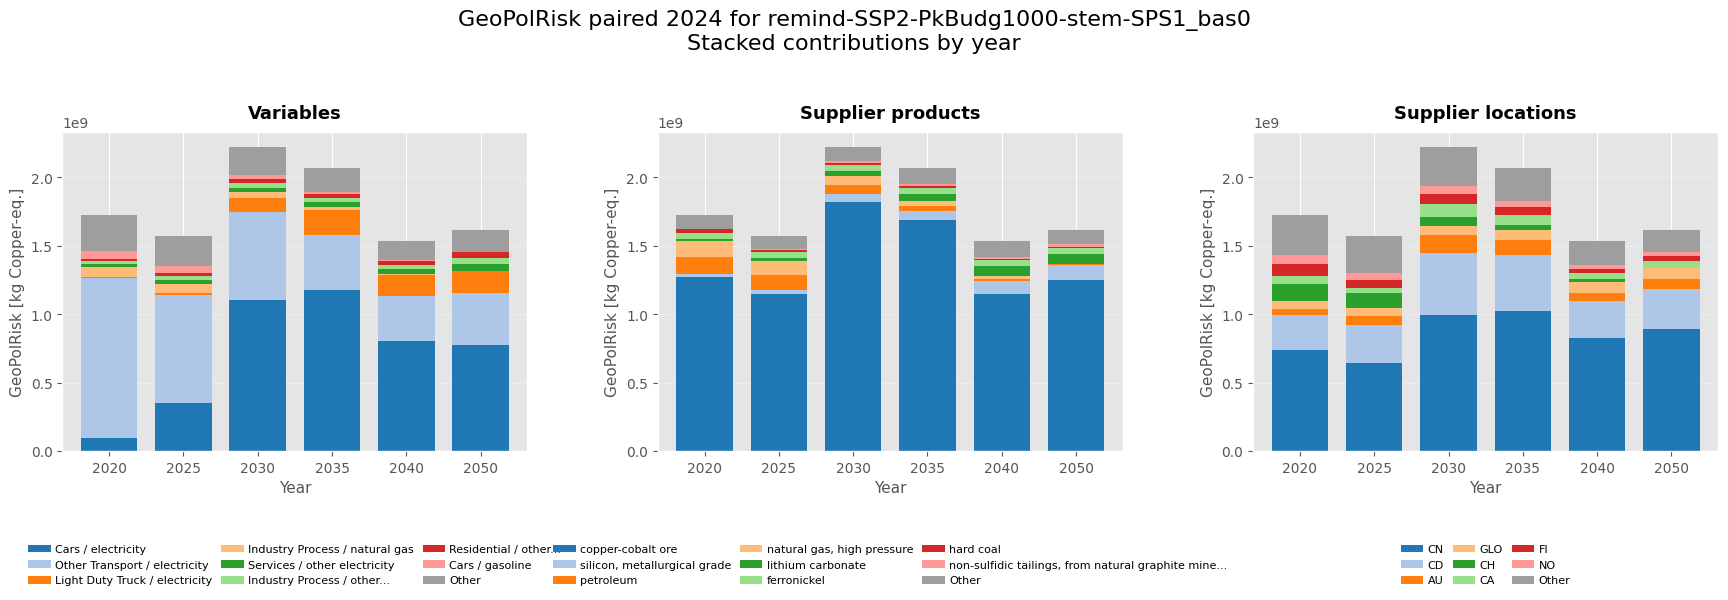

In [6]:
figure_path = Path(f"{TARGET_PACKAGE.stem}_geopolrisk_1x3_stacked.png")
excel_path = export_excel_report(df_results, df_contributors, TARGET_PACKAGE.stem, top_n=TOP_N)
edges_excel_path = export_edges_dataframe(df_contributors, TARGET_PACKAGE.stem, year=max(YEARS))
fig = make_figure(df_results, df_contributors, TARGET_PACKAGE.stem, top_n=TOP_N)
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
print(figure_path)
print(excel_path)
print(edges_excel_path)
print(contributors_file)
plt.show()


## All Scenarios

- This fast path runs every `*.zip` package in `dev/`.
- It skips EDGES contributor export entirely.
- It aggregates `act_category` and `location` in the results to keep the combined file lighter.
- It exports one combined parquet file and one end-user comparison workbook for `2020` vs `2050`.
- Supplier-product and supplier-location comparisons are not available in this fast mode.


In [ ]:
all_results_file, end_user_comparison_workbook, df_all_results = run_all_packages_results_only(
    ALL_PACKAGES,
    multiprocessing=MULTIPROCESSING,
    recompute_existing=RECOMPUTE_ALL_SCENARIOS,
    comparison_years=COMPARISON_YEARS,
    top_n=TOP_N,
    aggregate_by=ALL_SCENARIOS_AGGREGATE_BY,
)

print(all_results_file)
print(end_user_comparison_workbook)

pd.DataFrame(
    [
        {
            "packages": len(ALL_PACKAGES),
            "result_rows": len(df_all_results),
            "scenarios": df_all_results["scenario_label"].nunique() if not df_all_results.empty else 0,
            "comparison_years": COMPARISON_YEARS,
            "aggregate_by": ALL_SCENARIOS_AGGREGATE_BY,
        }
    ]
)
